In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "061a82116be00c585cab41d5b2a790e2a4f96d44"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/061a82116be00c585cab41d5b2a790e2a4f96d44/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Estimating Mutual Information

Every mutual information computed so far came out of a formula for the joint
density. Real pairs do not bring one along. We are handed a list, perhaps of
spoken sentences with their transcripts or of queries with the documents that
answered them, and from the list alone we want to say how much one member of
a pair tells us about the other. Representation learning goes a step further
and trains models to make that amount large, so the estimate becomes the
training objective.

A widely used loss makes the question concrete. A contrastive model such as
SimCLR or CLIP is trained on pairs, two crops of one photograph or an image
and its caption, which are called two *views* of one example. It learns to
pick the true partner of a view out of a batch of candidates, say $128$ of
them, and reports a cross-entropy loss, the InfoNCE loss. Papers often
subtract that loss from $\ln 128 = 4.85$ and quote the difference as the
information that the two views share. That number can never exceed
$4.85$ nats, however much the views share, because a model that always
picks the right partner has shown only that it can tell $128$ candidates
apart. Since models are trained on such numbers and papers read them as
measurements, we need to tell a measurement from a bound, and the slack of a
bound from the error of a model.

There are two routes. The direct one counts samples, in the cells of a
histogram or among the neighbors of each point. It works for a small amount
of information between two numbers and fails for vectors. The other
replaces the unknown densities by a model, built so that the result is a
lower bound on the information, and maximizes the bound. Two results matter
most: the limit on what any estimator can guarantee without assumptions
(that section), and the bound behind the
InfoNCE loss, with its ceiling (that section).

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
from scipy.spatial.distance import cdist
from scipy.special import digamma, logsumexp

## A Pair with Known Information

An estimator can be judged only where the answer is known. We test every one
on the standard Gaussian pair of that section with
correlation $\rho$, which shares

$$I(X; Y) = -\tfrac{1}{2}\log\left(1 - \rho^2\right)$$

nats: $0.83$ at $\rho = 0.9$ and $1.96$ at $\rho = 0.99$. Logarithms are
natural throughout.

The bounds of this section are built from the *pointwise mutual information*
(that section),
$\textrm{pmi}(x, y) = \log \frac{p(x, y)}{p(x)\,p(y)}$, which says how much
more likely a pair is under the joint distribution than under independence.
For the Gaussian pair it is a quadratic:

$$\textrm{pmi}(x, y) = -\tfrac{1}{2}\log(1 - \rho^2) - \frac{x^2 - 2\rho x y + y^2}{2(1 - \rho^2)} + \frac{x^2 + y^2}{2}.$$

Its average over pairs drawn from the joint distribution is $I(X; Y)$. The
average of its exponential over *independent* $x$ and $y$ is $1$, because
$p(x)\,p(y)\,e^{\textrm{pmi}(x, y)} = p(x, y)$ integrates to one. The cell
checks both facts on samples. For the second it pairs each $x$ with the $y$
of the neighboring sample, which destroys the dependence. We call these
*mismatched pairs*. Each of them is a draw of independent $x$ and $y$, and
they will stand in for such draws wherever a bound needs them.

In [3]:
def gauss_pair(rng, rho, n):
    """Samples of the standard Gaussian pair; n is a count or a shape."""
    x = rng.standard_normal(n)
    y = rho * x + np.sqrt(1 - rho**2) * rng.standard_normal(n)
    return x, y

def mi_gauss(rho):
    """I(X;Y) of the pair, in nats."""
    return -0.5 * np.log(1 - rho**2)

def pmi_gauss(x, y, rho):
    """Pointwise mutual information pmi(x, y) of the pair, in nats."""
    c = 1 - rho**2
    return (-0.5 * np.log(c) - (x**2 - 2 * rho * x * y + y**2) / (2 * c)
            + (x**2 + y**2) / 2)

rng = np.random.default_rng()
x, y = gauss_pair(rng, 0.9, 200_000)
print(f'I(X;Y) = {mi_gauss(0.9):.3f} nats, mean pmi over pairs = '
      f'{pmi_gauss(x, y, 0.9).mean():.3f}')
print(f'mean exp(pmi) over independent pairs = '
      f'{np.exp(pmi_gauss(x, np.roll(y, 1), 0.9)).mean():.3f}')

I(X;Y) = 0.830 nats, mean pmi over pairs = 0.828
mean exp(pmi) over independent pairs = 1.002


Both averages agree with their targets to about a hundredth. The bounds of
this section rest on these two identities, and the second will cause most
of the trouble. At $\rho = 0.9$ it is an average of tame numbers: the
variance of $e^{\textrm{pmi}}$ over independent pairs is $e^{2I} - 1$
(Exercise 2), which is $4.3$ here.
At $I = 6$ the variance is $160{,}000$, and the same $200{,}000$ samples
would leave the average uncertain by about $0.9$.

## Nonparametric Estimation

The obvious way to estimate a probability is to count the samples that fall
into a region. What remains to choose is the regions, and we begin with a
grid fixed in advance.

### Histograms

The simplest estimator cuts the range of each variable into $b$ intervals of
equal width, counts the samples in each of the $b \times b$ cells, and
applies the discrete definition of mutual information to the table of
frequencies. It makes two errors, and they have opposite signs.

The first is a loss. The bin of a value is a function of the value, and by
the data-processing inequality (that section) a function of $X$
shares with $Y$ at most what $X$ shares. Binning can only remove
information, and it removes a lot when the dependence is finer than a bin.
At $\rho = 0.99$ the standard deviation of $y$ given $x$ is
$\sqrt{1 - \rho^2} = 0.14$, while ten bins across a sample that reaches
from about $-4.5$ to $4.5$ are $0.9$ wide, six times as much.

The second is a gain that is not there. The estimate is the KL divergence
between the table of frequencies and the product of its row and column
sums. It is therefore never negative, and it is zero only if the table
factorizes exactly, which the fluctuating counts of an independent pair
never do. Sampling noise reads as dependence, the more so the fewer samples
a cell holds.

Besides its two errors the histogram has a ceiling. Its estimate cannot
exceed the entropy of the binned $x$, and $b$ bins hold at most $\log b$
nats: $2.30$ for ten bins, whatever the pair shares. We will meet such a
ceiling in every estimator of the section. None of them can report more than
the logarithm of the number of things it can tell apart.

The cell implements the estimator as `binned_mi` and applies it to
$200{,}000$ samples of four pairs with $b = 10$, $40$ and $160$: an
independent pair, the Gaussian pair at $\rho = 0.9$ and at $\rho = 0.99$,
and the pair $Y = X^2 + 0.3\,\epsilon$ of
that section, which has zero correlation and
shares $1.141$ nats.

In [4]:
def binned_mi(x, y, bins):
    """Plug-in MI of the bins x bins histogram of (x, y), in nats."""
    p = np.histogram2d(x, y, bins=bins)[0] / len(x)       # cell frequencies
    q = p.sum(axis=1, keepdims=True) * p.sum(axis=0, keepdims=True)
    nz = p > 0                                            # occupied cells
    return float((p[nz] * np.log(p[nz] / q[nz])).sum())

mi_parabola = 1.141  # by quadrature, sec_mdl-mi-nonlinear-correlation
n = 200_000
x = rng.standard_normal(n)
pairs = {'rho = 0': (gauss_pair(rng, 0.0, n), 0.0),
         'rho = 0.9': (gauss_pair(rng, 0.9, n), mi_gauss(0.9)),
         'rho = 0.99': (gauss_pair(rng, 0.99, n), mi_gauss(0.99)),
         'parabola': ((x, x**2 + 0.3 * rng.standard_normal(n)), mi_parabola)}
print('pair        truth  b = 10  b = 40  b = 160')
for name, ((u, v), truth) in pairs.items():
    print(f'{name:10}  {truth:5.3f}'
          + ''.join(f'  {binned_mi(u, v, b):6.3f}' for b in (10, 40, 160)))

pair        truth  b = 10  b = 40  b = 160
rho = 0     0.000   0.000   0.003   0.036


rho = 0.9   0.830   0.613   0.813   0.846
rho = 0.99  1.959   1.109   1.797   1.958


parabola    1.141   0.517   0.990   1.132


Both errors are in the table. With $b = 10$ every dependent pair reads low:
about $0.6$ for $0.83$ nats at $\rho = 0.9$, and roughly half of the truth
at $\rho = 0.99$ and for the pair on the parabola. With $b = 160$ the
independent pair is credited with a few hundredths of a nat, and the pair at
$\rho = 0.9$ reads above its true value, which binning alone could never
bring about. The entry for $\rho = 0.99$ at $b = 160$ lands within about
$0.01$ of the truth, but only because a loss and a gain partly cancel
there; the row above shows the same bins overshooting. With the truth
unknown, nothing in the sample says which column to believe.

A third weakness concerns the coordinates. An invertible map of either
variable leaves the mutual information unchanged
(that section), and it moves the bins.
Replace $x$ by $x^3$ in the pair at $\rho = 0.9$. The largest of
$200{,}000$ standard normal values is about $4.5$ in magnitude, so $x^3$
ranges over about $\pm 90$ and each of $40$ bins is about $4.5$ wide:
roughly nine samples in ten land in the two or three bins around zero. A
remedy is to bin the *ranks*, the positions of the values in the sorted
sample. An increasing map does not change them, and every bin of ranks
holds the same number of samples.

In [5]:
x, y = gauss_pair(rng, 0.9, n)
rank = lambda a: np.argsort(np.argsort(a))       # position in sorted order
print(f'true I = {mi_gauss(0.9):.3f} nats; histograms with b = 40:')
for name, u in (('x', x), ('x**3', x**3)):
    print(f'{name:4}: correlation {np.corrcoef(u, y)[0, 1]:.3f}, '
          f'raw {binned_mi(u, y, 40):.3f}, '
          f'ranks {binned_mi(rank(u), rank(y), 40):.3f} nats')

true I = 0.830 nats; histograms with b = 40:
x   : correlation 0.901, raw 0.813, ranks 0.816 nats


x**3: correlation 0.693, raw 0.324, ranks 0.816 nats


The information is still $0.830$ nats, yet the cube lowers the correlation
from $0.90$ to about $0.7$ and cuts the raw estimate to between $0.3$ and
$0.5$ nats. Where in that range a sample lands depends on its few largest
values, which set the width of the bins. The estimate from ranks is the same
for $x$ and for $x^3$, digit for digit, and within $0.02$ of the truth.

Ranks repair the coordinates. Nothing repairs the dimension. A pair of
five-dimensional vectors needs a histogram with ten axes, and ten bins on
each give $10^{10}$ cells, nearly all of them empty for any sample we can
collect. An estimator for vectors must let the data set the resolution, with
small cells where samples are dense and large cells where they are sparse.

### The KSG Estimator

The estimator of @Kraskov.Stogbauer.Grassberger.2004, KSG for short,
replaces fixed cells by neighborhoods of the sample points. It is the
standard tool for a pair of low-dimensional variables. This subsection and
the next can be skipped on a first reading.

Distances are measured by the largest coordinate difference (the Chebyshev
distance), so that a ball is a square in the plane and a box in higher
dimension. Around sample $i$ draw the smallest box in the joint $(x, y)$
space that reaches its $m$-th nearest neighbor, and call its half-width
$r_i$. The box holds the fraction $m/n$ of the $n$ samples, an estimate of
the joint probability near the point.

The two marginal probabilities are counted at the same scale. The strip
$|x - x_i| < r_i$ holds $n_x^{(i)}$ other samples and the strip
$|y - y_i| < r_i$ holds $n_y^{(i)}$. The shared half-width is what lets
counts stand for densities. If the densities are nearly constant over the
box, the box has probability about $p(x_i, y_i)\,(2r_i)^2$ and the strips
about $p(x_i)\,2r_i$ and $p(y_i)\,2r_i$, so the widths cancel when the
fraction in the box is divided by the product of the fractions in the
strips. The logarithm of that ratio is a pointwise mutual information
computed by counting. the figure shows the three counts at
one point.

![The KSG count at one sample point $i$ (the star), with $m = 3$. The box of half-width $r_i$ reaches the third nearest neighbor in the joint plane (the ring on its left edge; it lies in the horizontal strip and counts toward $n_y^{(i)}$ only); two neighbors lie strictly inside. The vertical strip of the same half-width holds $n_x^{(i)}$ other samples and the horizontal strip holds $n_y^{(i)}$ (blue and green dots lie in one strip only). The summand of the estimator is approximately $\log\frac{m/n}{(n_x/n)(n_y/n)}$, a pointwise mutual information from counts.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-ksg-box.svg)

Averaging these local log ratios over the sample estimates $I(X; Y)$. One
correction is needed, because the logarithm of a fraction of a handful of
points is a biased estimate of a log probability. The probability mass $p$
of the box that reaches the $m$-th of $n - 1$ neighbors has
$\mathbb{E}[\log p] = \psi(m) - \psi(n)$, not $\log(m/n)$, where
$\psi = (\log \Gamma)'$ is the digamma function. We do not derive this.
With $\psi$ in place of the logarithm the estimator reads

$$\hat{I}_{\textrm{KSG}} = \psi(m) + \psi(n) - \frac{1}{n} \sum_{i=1}^{n} \left(\psi\left(n_x^{(i)} + 1\right) + \psi\left(n_y^{(i)} + 1\right)\right).$$

Since $\psi(j) \approx \log j$ for large $j$, each summand is approximately
$\log\frac{m\,n}{n_x^{(i)}\, n_y^{(i)}}$, the local log ratio of the box
fraction to the product of the strip fractions. The $+1$ puts the strips on
the footing of the box: $\psi(m)$ belongs to a box whose boundary passes
through its $m$-th neighbor, and a strip with $n_x^{(i)}$ samples strictly
inside is treated as if its boundary passed through the next one. Both strip
counts use the strict inequality and exclude the point itself, so a neighbor
on the boundary of a strip is not counted. The radii $r_i$ adapt to the
data, and there is no bin width or bandwidth to choose.

The implementation counts the neighbors of all points at once from the
$n \times n$ matrices of Chebyshev distances in each space (`cdist`). The
joint distance is their elementwise maximum.

In [6]:
def ksg_counts(x, y, m=5):
    """Strip counts n_x, n_y of every sample point; x, y are (n, d)."""
    dx, dy = cdist(x, x, 'chebyshev'), cdist(y, y, 'chebyshev')
    d = np.maximum(dx, dy)                       # joint Chebyshev distance
    np.fill_diagonal(d, np.inf)
    r = np.partition(d, m - 1, axis=1)[:, m - 1]  # half-width: m-th neighbor
    n_x = (dx < r[:, None]).sum(axis=1) - 1      # strict, self excluded
    n_y = (dy < r[:, None]).sum(axis=1) - 1
    return n_x, n_y

def ksg_mi(x, y, m=5):
    """KSG nearest-neighbor estimate of I(X;Y) in nats; x, y are (n, d)."""
    n_x, n_y = ksg_counts(x, y, m)
    return float(digamma(m) + digamma(len(x))
                 - (digamma(n_x + 1) + digamma(n_y + 1)).mean())

Each summand of the equation involves only counts, and counting alone
bounds how large the estimate can be.

**Proposition (sample-size ceiling of KSG).** *For any sample of $n$ points
in which no two joint distances from the same point are equal,*

$$\hat{I}_{\textrm{KSG}} \leq \psi(n) - \psi(m),$$

*with equality when $Y = X$.*

**Proof.** Without ties, exactly $m - 1$ samples lie strictly closer to point
$i$ than its $m$-th neighbor. Each of them satisfies $|x_j - x_i| < r_i$ and
$|y_j - y_i| < r_i$, because the joint distance is the larger of the two
coordinate distances, so it lies in both strips: $n_x^{(i)} \geq m - 1$ and
$n_y^{(i)} \geq m - 1$. The digamma function is increasing, so each summand
is at most $\psi(m) + \psi(n) - 2\psi(m) = \psi(n) - \psi(m)$. For $Y = X$
the three distances coincide, both strips hold exactly the $m - 1$ points
inside the box, and every summand attains the bound. $\blacksquare$

At $n = 2{,}000$ and $m = 5$ the ceiling is $\psi(2000) - \psi(5) = 6.09$
nats, close to $\log(n/m) = 5.99$. A pair with infinite information, $Y = X$
for continuous $X$, is reported as $6.1$ nats, and doubling the sample raises
the ceiling by only about $\log 2$. This is the histogram's $\log b$ again,
with neighborhoods in place of bins: counting neighbors can report only as
much information as the sample has distinguishable neighborhoods, about
$n/m$ of them.

### KSG in High Dimension

In more dimensions the estimator fails well below its ceiling, and for a
different reason. Take $d$ independent copies of the pair, each with
$\rho = 0.9$, so that $X$ and $Y$ are $d$-dimensional. Information adds over
independent coordinates, because the log ratio is a sum of $d$ terms, so the
truth is $d \times 0.83$ nats.

The estimator rests on densities that are nearly constant over each box,
and in high dimension the boxes are too large for that. With $n = 2{,}000$
and $m = 5$ a box holds the fraction $m/n = 0.0025$ of the sample. Were the
sample spread evenly over its $2d$ dimensions, such a box would have sides
of $(m/n)^{1/(2d)}$ times the width of the data: $0.05$ at $d = 1$, but
$0.47$ at $d = 4$ and $0.83$ at $d = 16$. The dependence lives in a much
narrower band along $y = \rho x$. Given $x$, each coordinate of $y$ has
standard deviation $\sqrt{1 - \rho^2} = 0.44$, about $0.07$ of the width of
a sample that reaches from about $-3.3$ to $3.3$. A box several times wider than
the band fails as a coarse histogram cell does, and the estimate should fall
behind the truth as $d$ grows. The cell runs KSG on $2{,}000$ samples for
$d$ from $1$ to $16$ and measures by how much. It prints the average strip
count of each row, and it runs $Y = X$, which attains the ceiling.

In [7]:
n, rho = 2000, 0.9
print(' d  true I    KSG  mean strip count')
for dim in (1, 2, 4, 8, 16):
    x, y = gauss_pair(rng, rho, (n, dim))        # dim independent pairs
    n_x, n_y = ksg_counts(x, y)
    print(f'{dim:2d}  {dim * mi_gauss(rho):6.2f}  {ksg_mi(x, y):5.2f}  '
          f'{(n_x.mean() + n_y.mean()) / 2:16.1f}')
x = rng.standard_normal((n, 1))
print(f'Y = X:  KSG = {ksg_mi(x, x):.2f}, '
      f'ceiling psi(n) - psi(m) = {digamma(n) - digamma(5):.2f} nats')

 d  true I    KSG  mean strip count


 1    0.83   0.84              71.3
 2    1.66   1.61              49.5


 4    3.32   2.54              30.7


 8    6.64   2.87              25.3


16   13.29   2.79              26.2


Y = X:  KSG = 6.09, ceiling psi(n) - psi(m) = 6.09 nats


In one and two dimensions KSG lands within about $0.1$ nat of the truth. At
$d = 4$ it reports about $2.5$ for $3.3$, almost a nat low. Then it stops:
at $d = 8$ and at $d = 16$ it reports a little under $3$ nats, although the
truth doubles between these rows, to $13.3$. The ceiling is not to blame,
since that is less than half of the $6.1$ nats printed for $Y = X$.

The strip counts show the saturation directly. Each summand is about
$\log\frac{m\,n}{n_x n_y}$, so the estimate grows only if the strips empty
out. They hold about $70$ of the $2{,}000$ points at $d = 1$ and about $31$
at $d = 4$, and then stay at about $26$. A box as local as the one at
$d = 1$ would need $m/n = 0.05^{32}$ at $d = 16$, a sample of some
$10^{42}$ points. The sample that keeps neighborhoods small grows
exponentially with the dimension.

### Limits of Distribution-Free Estimation

Perhaps a cleverer estimator does better. Ask only for a lower bound: a
function $B$ of $n$ samples such that $B \leq I(X; Y)$ with probability at
least $0.95$ *for every distribution* of the pair. (Any level above one
half would serve.) Lower bounds are the useful direction, because a
representation learner wants to be sure that two views share a lot.

The smallest case shows the obstacle. Let $Y = X$ be a copy of a discrete
variable, so that $I(X; Y) = H(X)$. An estimator that treats the symbols as
labels without meaning cannot use which values it saw. It can use only the
pattern of repetitions: how many distinct values occur once in the sample,
how many occur twice, and so on. This pattern is the *type* of the sample,
and we suppose that $B$ is a function of it. Four steps give the limit, and
the third is the one to watch.

1. Let $X$ be uniform on $M$ symbols and draw $n$ samples. Two given samples
   coincide with probability $1/M$, so by the union bound some two of the
   $n(n-1)/2$ pairs coincide with probability at most $n(n-1)/(2M)$.
1. Apply the guarantee to the uniform distribution on $M = n^2$ symbols,
   whose entropy is $2 \log n$: on a sample from *that* distribution,
   $B \leq 2 \log n$ with probability at least $0.95$.
1. By the first step, a sample from that distribution consists of $n$
   distinct values with probability more than $\tfrac{1}{2}$. Two events
   whose probabilities add to more than $1$ overlap, so $B \leq 2 \log n$
   on some all-distinct sample.
1. All samples of $n$ distinct values have the same type, so $B$ reports at
   most $2 \log n$ on every one of them, whatever source produced it.

Now take $M = 2^{256}$ symbols, entropy $256 \ln 2 = 177$ nats. At
$n = 10^6$ the sample is all distinct with probability at least
$1 - 4.3 \times 10^{-66}$, and on that sample $B$ reports at most
$2 \log 10^6 = 27.6$ nats. A million samples cannot guarantee $177$ nats,
and they cannot guarantee $30$. Exercise
6 sharpens the
constant and asks what sample would suffice.

@McAllester.Stratos.2020 proved the general statement, without the
assumption on types:

> **Theorem (McAllester–Stratos, informal).** Any distribution-free lower
> bound on $I(X; Y)$ that holds with fixed confidence from $n$ samples is
> $O(\log n)$.

The invariance of mutual information is part of the reason. An invertible
relabelling of either variable leaves the information unchanged
(that section), so an estimator that assumes
nothing about the coordinates must cope with every relabelling of the
sample at once, and all it can rely on is the pattern of repetitions.
Whoever wants more must assume something. KSG assumes that distances in the
given coordinates mean something and that the density is smooth in them, and
what it offers in return is an estimate without a guarantee. The bounds of
that section can report more than the logarithm
of their sample size, and that section shows what such
a report is worth.

### The Compression-Phase Debate

Both limits met so far, a histogram that depends on its bins and a sample
that cannot show more than the logarithm of its size, bear on a well-known
experiment.
@Shwartz-Ziv.Tishby.2017 took a small classifier whose inputs are
the $4{,}096$ binary patterns of $12$ bits, binned the activations of each
layer $Z$ during training, and plotted the estimates of $I(X; Z)$ and
$I(Y; Z)$, with input $X$ and label $Y$. They reported a short *fitting*
phase, in which both rise, and a long *compression* phase, in which
$I(X; Z)$ falls while $I(Y; Z)$ holds, and they proposed compression as the
reason why deep networks generalize. @Saxe.Bansal.Dapello.ea.2018
found the compression phase with saturating activations such as $\tanh$ and
not with ReLU, whose networks generalize as well.

What had been measured? In a deterministic network the binned layer
$Z_{\textrm{bin}}$ is a function of the input, so
$H(Z_{\textrm{bin}} \mid X) = 0$ and the estimate is
$I(X; Z_{\textrm{bin}}) = H(Z_{\textrm{bin}})$, the entropy of the binned
activations. It is at most the logarithm of the number of inputs,
$\ln 4096 = 8.3$ nats in the original experiment, and it falls whenever
inputs that occupied different cells come to share one, as they do when
training pushes saturating units into the two edge bins. The information
itself does not move. As long as different inputs give different
activations, $I(X; Z) = H(X)$ for a finite set of inputs, and for
continuous inputs it is infinite (that section). The
curves track how the activations spread over the bins, which is a property
of the estimator (Exercise
10).

## Variational Lower Bounds

Counting cannot measure a large mutual information, so the second route asks
for less. The densities in $\log\frac{p(x, y)}{p(x)\,p(y)}$ are unknown, and
a variational method replaces them by an auxiliary model, chosen so that the
expectation it leads to is a *lower bound* on the information whatever the
model is. Training the model to make that expectation large tightens the
bound and can never carry it past $I(X; Y)$. The estimation problem has
become an optimization problem. Its answer carries two errors: that of the
model, which may be far from the best one, and that of the sample, since a
batch average has to stand in for the expectation.

Four bounds of this kind follow. The first comes from a decoder
(Barber–Agakov). The next two come from a function that scores pairs and
needs no normalization: the Donsker–Varadhan bound and the bound of Nguyen,
Wainwright and Jordan, NWJ for short. The fourth, InfoNCE, has a section of
its own. @Poole.Oord.Alemi.ea.2019 treat the four in one framework.
All the proofs use a single tool, Gibbs' inequality
(that section): a KL divergence is never negative.

### The Barber–Agakov Bound

The first bound replaces the unknown posterior $p(x \mid y)$ by a model of it.

**Proposition (Barber–Agakov bound).** *For any conditional density
$q(x \mid y)$,*

$$I(X; Y) \geq H(X) + \mathbb{E}_{(x,y) \sim P_{X,Y}}\left[\log q(x \mid y)\right],$$

*with equality if and only if $q(x \mid y) = p(x \mid y)$. For continuous
$X$ the differential entropy $h(X)$ takes the place of $H(X)$.*

**Proof.** Write $I(X; Y) = H(X) - H(X \mid Y)$ and insert the model:

$$
I(X; Y) - H(X) - \mathbb{E}\left[\log q(x \mid y)\right]
= \mathbb{E}\left[\log \frac{p(x \mid y)}{q(x \mid y)}\right]
= \mathbb{E}_{y}\left[D_{\textrm{KL}}\big(p(\cdot \mid y) \,\|\, q(\cdot \mid y)\big)\right]
\geq 0
$$

by Gibbs' inequality, applied for each value of $y$ and averaged. Equality
holds if and only if every divergence vanishes, that is, when $q$ is the
posterior. $\blacksquare$

The bound [@Barber.Agakov.2003] is the information-theoretic reading of
an encoder–decoder: if a decoder reconstructs $X$ from $Y$ with low
cross-entropy, the pair must share a lot of information. Its weak point is
$H(X)$, which is unknown in the situations where we need the bound. It is a
constant, however, so *maximizing* the bound over $q$ never needs it.
Substituting $H(X) = -\mathbb{E}\log p(x)$ gives the equivalent ratio form
$I(X; Y) \geq \mathbb{E}\left[\log \left(q(x \mid y)/p(x)\right)\right]$,
which the proof of the InfoNCE bound will use.

We say that a model *certifies* the value of its bound. The word refers to
the inequality between expectations. An average over a batch only estimates
the certified value and can land on either side of it.

A classifier is a decoder of the label. To see what it certifies, exchange
the roles of the variables, which the symmetry of $I$ allows, and take the
classifier as the model $q(y \mid x)$. The bound is then the loss
certificate of that section: for $k$ balanced
classes and held-out cross-entropy $L$, $I(X; Y) \geq \log k - L$. Since
$L \geq 0$, no 10-class classifier certifies more than $\ln 10 = 2.30$
nats. The InfoNCE bound will have this shape.

The Gaussian pair shows what a poor decoder loses. A decoder trained by
squared error alone is a Gaussian $q(x \mid y) = \mathcal{N}(x; a y, 1)$
with unit variance. With $h(X) = \tfrac{1}{2}\log(2\pi e)$ the bound becomes
$\tfrac{1}{2} - \tfrac{1}{2}\mathbb{E}(X - aY)^2 = \tfrac{1}{2} - \tfrac{1}{2}(1 - 2a\rho + a^2)$,
which is largest at $a = \rho$, where it equals $\rho^2/2$. At $\rho = 0.9$
this decoder certifies $0.41$ nats of the true $0.83$, and it never
certifies more than $\tfrac{1}{2}$ however strong the dependence. The
shortfall is the error of a decoder whose variance is fixed at $1$ instead
of the true conditional variance $1 - \rho^2$ (Exercise
4).

### The Donsker–Varadhan Bound

The second bound needs neither a normalized model nor $H(X)$. Mutual
information is itself a KL divergence, from the joint distribution to the
product of the marginals (that section), so it
suffices to bound a KL divergence from below. The bound does so through an
arbitrary function $T$ that scores a point, a *critic* as in
that section, and nothing in it has to integrate to one.

**Proposition (Donsker–Varadhan bound).** *For distributions $P$ and $Q$ and
any function $T$ for which $\mathbb{E}_P[T]$ is defined and
$\mathbb{E}_Q[e^T] < \infty$,*

$$D_{\textrm{KL}}(P \| Q) \geq \mathbb{E}_P[T] - \log \mathbb{E}_Q\left[e^{T}\right],$$

*with equality if and only if $T = \log \frac{dP}{dQ} + c$ for a constant
$c$. When $P \ll Q$ and the divergence is finite, the supremum over $T$
therefore attains $D_{\textrm{KL}}(P \| Q)$, which is the Donsker–Varadhan
representation of the divergence* [@Donsker.Varadhan.1983].

**Proof.** If $P$ is not absolutely continuous with respect to $Q$, the left
side is infinite. Otherwise, given $T$, tilt $Q$ by the critic: let
$\tilde{Q}$ be the *tilted distribution* with density
$\tilde{q}(x) = q(x)\, e^{T(x)} / Z$ and normalizer
$Z = \mathbb{E}_Q[e^T]$. Then

$$
D_{\textrm{KL}}(P \| Q) - \left(\mathbb{E}_P[T] - \log Z\right)
= \mathbb{E}_P\left[\log \frac{p}{q} - T + \log Z\right]
= \mathbb{E}_P\left[\log \frac{p}{\tilde{q}}\right]
= D_{\textrm{KL}}(P \| \tilde{Q}) \geq 0,
$$

by Gibbs' inequality. Equality holds if and only if $P = \tilde{Q}$, which
means $p/q = e^{T}/Z$, or $T = \log(p/q) + \log Z$. $\blacksquare$

The gap of the bound is the divergence from $P$ to the tilted distribution,
so a critic is good when tilting $Q$ by $e^T$ reproduces $P$. A constant
added to $T$ cancels between the two terms and changes nothing. Specializing
to $P = P_{X,Y}$ and $Q = P_X \otimes P_Y$ bounds mutual information: for
any critic $T(x, y)$,

$$
I(X; Y) \geq \mathbb{E}_{P_{X,Y}}[T] - \log \mathbb{E}_{P_X \otimes P_Y}\left[e^{T}\right],
$$

and the best critic is the pmi plus any constant. The first expectation is
an average over the sample pairs. The second needs independent pairs, and
the mismatched pairs of a batch supply them. With a neural network as the
critic, this estimator is known as *MINE*, for mutual information neural
estimation [@Belghazi.Baratin.Rajeshwar.ea.2018].

### The NWJ Bound

The logarithm in front of $\mathbb{E}_Q[e^T]$ makes trouble on a minibatch.
By Jensen's inequality the logarithm of a batch average is on average below
the logarithm of the population average, so the batch value
$\overline{T} - \log \overline{e^T}$ of the DV bound is on average too high.
An estimate of a lower bound should not err upward.

The tangent-line inequality $\log z \leq z/e$, with equality at $z = e$,
removes the logarithm: applied to $Z = \mathbb{E}_Q[e^T]$ in
the equation, it gives, for every critic $T$,

$$I(X; Y) \geq \mathbb{E}_{P_{X,Y}}[T] - e^{-1}\, \mathbb{E}_{P_X \otimes P_Y}\left[e^{T}\right].$$

This is the *NWJ bound* [@Nguyen.Wainwright.Jordan.2010]. For the same
critic it is never larger than the DV bound, and the two agree only when
$Z = e$. It is tight at $T^* = 1 + \textrm{pmi}$: where DV accepts the pmi
plus any constant, NWJ insists on the constant $1$. Since
$e^{-1}\, \mathbb{E}_Q[e^T] = \mathbb{E}_Q[e^{T-1}]$, it is the critic bound
that that section gives for every f-divergence, written out
for the KL divergence:
$D_{\textrm{KL}}(P \| Q) \geq \mathbb{E}_P[T] - \mathbb{E}_Q[e^{T-1}]$,
obtained there from the convex conjugate of $u \log u$. For this one
divergence, then, DV sharpens the general bound.

No logarithm of an average appears, so the batch value of
the equation is an unbiased estimate of the bound. Unbiased is
not the same as reliable. For the optimal critic, $e^{T^*-1} = e^{\textrm{pmi}}$
is the density ratio. Its expectation over independent pairs is $1$, but when
$X$ and $Y$ are strongly dependent that expectation is carried by a few
enormous values among many that are close to zero, and a batch without an
enormous value reports too much. that section works
out how much, and measures it.

## InfoNCE

### The Contrastive Loss

The $e^T$ of the DV and NWJ bounds is unnormalized, so a single pair can
dominate a batch. InfoNCE normalizes it within the batch: it makes the
candidates compete. Draw one *positive* pair $(x, y^+) \sim P_{X,Y}$, whose
first member $x$ we call the *anchor*, and $N - 1$ *negatives*
$y_2, \ldots, y_N$ drawn independently from $P_Y$. Score every candidate
with the critic $T(x, y)$, and ask a softmax over the $N$ scores to point at
the positive. The *InfoNCE loss* [@Oord.Li.Vinyals.2018] is the
resulting cross-entropy,

$$\mathcal{L}_{\textrm{NCE}} = -\mathbb{E}\left[\log \frac{e^{T(x, y^+)}}{e^{T(x, y^+)} + \sum_{j=2}^{N} e^{T(x, y_j)}}\right],$$

where the expectation is over the positive pair and the negatives. The
associated estimate of mutual information is the logarithm of the number of
candidates minus the loss,

$$\hat{I}_{\textrm{NCE}} = \log N - \mathcal{L}_{\textrm{NCE}}.$$

Some papers write the denominator as the average
$\frac{1}{N}\sum_j e^{T(x, y_j)}$; the expected logarithm of the ratio is
then $\hat{I}_{\textrm{NCE}}$ itself. The loss is an $N$-class
cross-entropy whose classes are the other examples in the batch rather than
fixed labels. It is the loss of CPC, SimCLR and CLIP
[@Oord.Li.Vinyals.2018; @Chen.Kornblith.Norouzi.ea.2020; @radford2021learning],
where $x$ and $y$ are two views or two modalities of one example and the
batch supplies the negatives.

![The InfoNCE task. Left: an anchor $x$ is scored by the critic against the positive $y^+$, drawn jointly with it, and $N-1$ negatives drawn independently from the marginal; the rays carry the scores $T(x, y_j)$. Right: a softmax over the $N$ scores must point at the positive. The resulting cross-entropy certifies $I(X;Y) \geq \log N - \mathcal{L}_{\textrm{NCE}}$, a bound that can never exceed $\log N$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-infonce-pos-neg.svg)

the figure shows the task. Its smallest case is
$N = 2$: with a single negative, the loss is the binary cross-entropy of
telling the true partner from the other candidate. Even a perfect answer
shows only that one of two candidates was right, and the estimate is at
most $\ln 2 = 0.69$ nats.

### The InfoNCE Bound

The proposition says that a small loss certifies information, and that the
certificate has a ceiling [@Poole.Oord.Alemi.ea.2019].

**Proposition (InfoNCE bound).** *For any measurable critic $T$ and any
$N \geq 1$,*

$$I(X; Y) \geq \log N - \mathcal{L}_{\textrm{NCE}}.$$

*The right-hand side is at most $\log N$.*

**Proof.** Number the candidates $y_1 = y^+, y_2, \ldots, y_N$ and write
$V = (Y_1, \ldots, Y_N)$ for the whole bag. The negatives $Y_{2:N}$ are
independent of the pair $(X, Y_1)$. The proof replaces $Y$ by the bag, finds
a normalized model of the bag given $X$, and applies Barber–Agakov.

*Step 1: independent negatives add no information.* The chain rule for
mutual information (that section) splits the
information in the bag,
$I(X; Y_1, Y_{2:N}) = I(X; Y_1) + I(X; Y_{2:N} \mid Y_1)$. Given $Y_1$, the
negatives are still independent of $X$, because they are independent of
$(X, Y_1)$; the second term is therefore $0$, and $I(X; V) = I(X; Y)$.

*Step 2: the softmax ratio is a normalized model.* This is the step that is
not routine. Define

$$
\gamma(x, v) = \frac{e^{T(x, y_1)}}{\frac{1}{N}\sum_{j=1}^N e^{T(x, y_j)}},
$$

which lies between $0$ and $N$. Let $p(v)$ be the distribution of a bag of
$N$ independent draws from $P_Y$, the positive slot included. The $N$
candidates of such a bag are independent and identically distributed, so
permuting them does not change the distribution of the bag. The $N$ ratios
$e^{T(x, y_i)} / \frac{1}{N}\sum_j e^{T(x, y_j)}$ therefore have the same
expectation, and for every fixed $x$

$$
\mathbb{E}_{p(v)}\left[\gamma(x, V)\right]
= \frac{1}{N}\sum_{i=1}^{N} \mathbb{E}_{p(v)}\left[\frac{e^{T(x, Y_i)}}{\frac{1}{N}\sum_{j} e^{T(x, Y_j)}}\right]
= \mathbb{E}_{p(v)}\left[\frac{\frac{1}{N}\sum_{i} e^{T(x, Y_i)}}{\frac{1}{N}\sum_{j} e^{T(x, Y_j)}}\right] = 1.
$$

Hence $q(v \mid x) = p(v)\, \gamma(x, v)$ is a conditional distribution over
bags.

*Step 3: Barber–Agakov on the bag.* The marginal distribution of the bag
$V$ is $p(v)$, because the positive is marginally a draw from $P_Y$ and is
independent of the negatives. Apply the ratio form of
the equation to the pair $(X, V)$ with the model $q(v \mid x)$,
the two variables' roles exchanged, which the symmetry of $I$ allows:

$$
I(X; V) \geq \mathbb{E}_{p(x, v)}\left[\log \frac{q(v \mid x)}{p(v)}\right]
= \mathbb{E}\left[\log \gamma(X, V)\right]
= \log N - \mathcal{L}_{\textrm{NCE}}.
$$

The last equality holds because $\log \gamma$ is $\log N$ plus the log-softmax
probability of the positive. With Step 1 this proves the bound. The softmax
probability of the positive is at most $1$, so $\mathcal{L}_{\textrm{NCE}} \geq 0$
and the right-hand side is at most $\log N$. $\blacksquare$

Naming the right partner out of $N$ candidates, even with certainty,
demonstrates $\log N$ nats, the information in one choice among $N$; no
critic can make that choice show more. The ten-class classifier that could
not certify more than $\ln 10$ faced the same task with the labels as
candidates. A larger $N$ raises the ceiling, which is the reason usually
given for the large batches of CPC, SimCLR and CLIP. The loss is smallest
for the critics $T^*(x, y) = \textrm{pmi}(x, y) + c(x)$, with any function
$c$ of the anchor alone (Exercise
7).

### The Ceiling with an Exact Critic

One might guess that with the exact critic $T = \textrm{pmi}$ the estimate
follows the truth up to $\log N$ and stops there. Inserting
$T = \textrm{pmi}$ into the loss shows what happens instead:

$$\hat{I}_{\textrm{NCE}} = I(X; Y) - \mathbb{E}\left[\log \frac{1}{N}\sum_{j=1}^N e^{\textrm{pmi}(x, y_j)}\right].$$

The estimate is the truth minus a correction. The correction is the bound's
own slack, so it is nonnegative by the proposition, and we can say roughly
how large it is. The average inside the logarithm has two parts. The $N - 1$
negatives are independent of $x$, so each of their terms has mean $1$ (the
second of the two identities we checked at the start), and together they
contribute about $1$. The positive contributes
$e^{\textrm{pmi}(x, y^+)}/N$, which is about $e^I/N$ for a typical pair.
Replacing both parts by these values gives

$$\hat{I}_{\textrm{NCE}} \approx I - \log\left(1 + \frac{e^I}{N}\right) = -\log\left(e^{-I} + \frac{1}{N}\right).$$

The second form is a smooth minimum of $I$ and $\log N$. It is close to $I$
while $e^I$ is much smaller than $N$, close to $\log N$ when $e^I$ is much
larger, and below both in between: at $I = \log N$ it reads $\log N - \log 2$,
which is $0.69$ nats short of either. The guess overlooked that the positive
sits in its own denominator, next to negatives that average $1$, and it
dominates the sum only when $e^I$ far exceeds $N$.

Replacing a heavy-tailed sum by its mean is a rough step, so the
approximation needs a test. For $N = 128$ and $I = 4$ it predicts $3.6$
nats, although the ceiling $\ln 128 = 4.85$ leaves room for the truth. The
cell scores all $N \times N$ pairs of a batch at once: row $i$ holds anchor
$x_i$ against every $y_j$, its diagonal entry is the positive, and the other
$N - 1$ entries are its negatives. The rows share their candidates, which
the proposition permits (Exercise
8). The cell sweeps the true
information for $N = 16$, $128$ and $1024$, whose ceilings $\ln N$ are
$2.77$, $4.85$ and $6.93$ nats, and prints the estimates at three levels.

I = 1:  N = 16: 0.89   N = 128: 0.98   N = 1024: 1.00
I = 4:  N = 16: 2.54   N = 128: 3.68   N = 1024: 3.95
I = 7:  N = 16: 2.76   N = 128: 4.75   N = 1024: 6.31


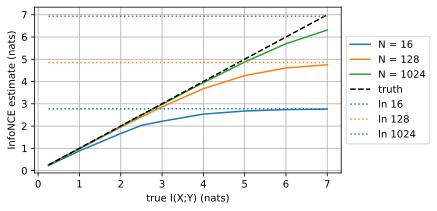

In [8]:
def infonce_bound(f):
    """log N minus the InfoNCE loss of an N x N score matrix f[i, j]."""
    return np.log(len(f)) + np.mean(np.diag(f) - logsumexp(f, axis=1))

def exact_scores(x, y, rho):
    """The exact critic T = pmi on all N x N pairs (x_i, y_j) of a batch."""
    return pmi_gauss(x[:, None], y[None, :], rho)

true_mi = np.array([0.25, 0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 7])
rhos = np.sqrt(1 - np.exp(-2 * true_mi))                 # invert mi_gauss
Ns = (16, 128, 1024)
ests = np.array([[np.mean([infonce_bound(exact_scores(*gauss_pair(rng, r, N), r))
                            for _ in range(200 if N <= 128 else 50)])
                  for r in rhos] for N in Ns])              # (N, level)
ceilings = [[np.log(N)] * len(true_mi) for N in Ns]
d2l.plot(true_mi, [*ests, true_mi, *ceilings], 'true I(X;Y) (nats)',
         'InfoNCE estimate (nats)',
         legend=[f'N = {N}' for N in Ns] + ['truth'] + [f'ln {N}' for N in Ns],
         fmts=('C0-', 'C1-', 'C2-', 'k--', 'C0:', 'C1:', 'C2:'),
         figsize=(5.5, 3), legend_loc='outside')
for I in (1, 4, 7):
    k = list(true_mi).index(I)
    print(f'I = {I}:  ' + '   '.join(f'N = {N}: {e:.2f}'
                                     for N, e in zip(Ns, ests[:, k])))

No curve has a corner. Each leaves the diagonal early and bends smoothly
toward its ceiling, and all nine printed values lie within $0.1$ nat of
the equation. At $I = 1$ every batch size is
within about $0.1$ nat of the truth. At $I = 4$ a batch of $128$ reports
$3.7$, and even $N = 1024$ falls a little short. At $I = 7$, just above its
ceiling of $6.93$, $N = 1024$ reports $6.3$.

Two exact statements stand behind the approximation. The average inside the
logarithm is at least the positive's own term $e^{\textrm{pmi}(x, y^+)}/N$,
so the correction is at least
$\mathbb{E}[\textrm{pmi}(x, y^+)] - \log N = I - \log N$, which is the
ceiling again. And the correction vanishes only as $N \to \infty$ (Exercise
7). The ceiling is the
crudest consequence of this slack.

The smooth minimum also makes the estimate hard to invert. With $N = 128$ a
reading of $3.7$ stands for $4$ nats and a reading near $4.75$ for $7$, so
the top $1.2$ nats of the scale hold every truth from $4$ nats to infinity.

Classification gives these numbers a scale. If each of two views of an image
determines its label among $1{,}000$ balanced classes, the label is a
function of either view, and by the data-processing inequality
(that section) the views share at least its entropy,
$\ln 1000 = 6.91$ nats. A loss with $128$ candidates cannot show that much,
and with $N = 1024$ the estimate is still $6.3$ when the views share $7$.
Whether two views carry enough for classification cannot be read off such a
number.

### Exact Critics Compared

The three bounds can now be compared on equal terms: $N = 128$, and the
exact critic $T^* = 1 + \textrm{pmi}$ for each (adding a constant does not
change InfoNCE). DV and NWJ take their independent pairs from the $N$
mismatched pairs of the batch, and the enormous values of the NWJ subsection
let us predict the outcome. A pair that is typical under the joint
distribution has pmi near $I$. Such pairs have probability about $e^{-I}$
under independence, because there
$p(x)\,p(y) = p(x, y)\,e^{-\textrm{pmi}}$. So about one mismatched pair in
$e^I$ could pass for a true pair. Each of these *rare pairs* has
$e^{\textrm{pmi}}$ near $e^I$, and together they carry
$\mathbb{E}[e^{\textrm{pmi}}] = 1$. A batch holds about $N e^{-I}$ of them:
six at $I = 3$, two at $I = 4$, and $0.3$ at $I = 6$.

While a batch holds several rare pairs, its average of $e^{\textrm{pmi}}$ is
near $1$ and the three bounds should agree. When the count falls below one,
most batches hold none. Call such a batch *starved*. Its average of
$e^{\textrm{pmi}}$ is near zero. On it NWJ reports the batch average of
$T^*$ minus almost nothing, about $1 + I$ and one nat high. DV reports the
average pmi minus the logarithm of a near-zero average, many nats high.

NWJ is unbiased, so something must make up for the starved batches. It is
the batch that is *hit*, one that holds a mismatched pair with
$e^{\textrm{pmi}} \geq N$. That one pair adds at least $1$ to the batch
average of $e^{\textrm{pmi}}$ and takes at least a nat off NWJ, which then
reads about $I$ or less, now and then far less. At $I = 6$ a rare pair has
$e^{\textrm{pmi}}$ near $e^6 = 403$, more than $N$, so a batch that holds
one is hit. With a mean count of $0.3$ that is roughly one batch in four,
and most of the others should be starved.

InfoNCE normalizes within the batch, so a negative that passes for a partner
spoils at most one row of the softmax. It should be steady, and it should
sit where the equation puts it, at $4.6$ nats for
$I = 6$. The dividing line $N e^{-I} \approx 1$ is $I \approx \ln N$. The
logarithm of the batch size limits DV and NWJ as well, only their values do
not show it.

The cell draws $200$ batches at each level and prints the median and the
quartiles of the batch values, which describe heavy tails better than a
standard deviation does, and the mean for NWJ. Its last two columns give the
share of starved batches, counted as those whose average of
$e^{\textrm{pmi}}$ over the mismatched pairs is below $0.1$, and the share
of hit batches. The plot shows the three medians.

  I  DV median [IQR]       NWJ median [IQR]      NWJ mean  InfoNCE median [IQR]  <0.1   >=N


0.5   0.50 [ 0.42,  0.58]   0.50 [ 0.41,  0.57]      0.49   0.49 [ 0.44,  0.54]    0%    0%


1.0   1.01 [ 0.92,  1.12]   1.01 [ 0.91,  1.11]      1.00   0.99 [ 0.93,  1.04]    0%    0%


2.0   2.04 [ 1.85,  2.24]   2.04 [ 1.84,  2.22]      2.02   1.96 [ 1.90,  2.01]    0%    0%


3.0   3.15 [ 2.83,  3.48]   3.14 [ 2.81,  3.38]      3.04   2.87 [ 2.80,  2.94]    0%    4%


4.0   4.07 [ 3.65,  4.72]   4.06 [ 3.59,  4.51]      4.01   3.68 [ 3.62,  3.73]    6%    4%


5.0   5.76 [ 4.67,  8.72]   5.50 [ 4.62,  5.93]      5.05   4.26 [ 4.21,  4.31]   32%   30%
6.0  10.43 [ 5.17, 29.22]   6.90 [ 4.74,  7.03]      5.74   4.61 [ 4.57,  4.63]   56%   33%


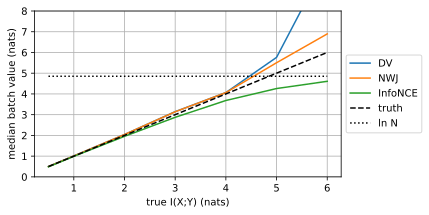

In [9]:
def quartiles(a):
    """Median and quartiles of a list of batch values, as text."""
    q1, med, q3 = np.percentile(a, [25, 50, 75])
    return f'{med:5.2f} [{q1:5.2f}, {q3:5.2f}]'

N, true_mi = 128, np.array([0.5, 1, 2, 3, 4, 5, 6])
medians = []
# Last two columns: share of batches whose mean e^pmi over mismatched pairs
# is below 0.1, and share holding a mismatched pair with e^pmi >= N.
print(f'{"I":>3}  {"DV median [IQR]":20}  {"NWJ median [IQR]":20}  '
      f'{"NWJ mean":>8}  {"InfoNCE median [IQR]":20}  {"<0.1":>4}  {">=N":>4}')
for I in true_mi:
    rho, batches = np.sqrt(1 - np.exp(-2 * I)), []
    for _ in range(200):
        x, y = gauss_pair(rng, rho, N)
        T_joint = 1 + pmi_gauss(x, y, rho)               # T* on true pairs
        T_prod = 1 + pmi_gauss(x, np.roll(y, 1), rho)    # T* on mismatched
        e_pmi = np.exp(T_prod - 1)                       # e^pmi, mismatched
        batches.append((T_joint.mean() - (logsumexp(T_prod) - np.log(N)),  # DV
                        T_joint.mean() - e_pmi.mean(),                     # NWJ
                        infonce_bound(exact_scores(x, y, rho)),
                        e_pmi.mean() < 0.1, e_pmi.max() >= N))
    dv, nwj, nce, low, rare = np.array(batches).T
    medians.append([np.median(a) for a in (dv, nwj, nce)])
    print(f'{I:3.1f}  {quartiles(dv)}  {quartiles(nwj)}  {nwj.mean():8.2f}'
          f'  {quartiles(nce)}  {low.mean():4.0%}  {rare.mean():4.0%}')
d2l.plot(true_mi, [*np.array(medians).T, true_mi, [np.log(N)] * len(true_mi)],
         'true I(X;Y) (nats)', 'median batch value (nats)',
         legend=['DV', 'NWJ', 'InfoNCE', 'truth', 'ln N'], ylim=[0, 8],
         fmts=('C0-', 'C1-', 'C2-', 'k--', 'k:'), figsize=(5.5, 3),
         legend_loc='outside')

Up to $I = 3$ the three medians are within about $0.2$ nat of the truth,
hardly any batch is starved or hit, and InfoNCE has the narrowest spread.
Starved batches appear where the count put them: no more than about one in
ten at $I = 4$, about a third at $I = 5$, and more than half at $I = 6$.

In that last row NWJ's median is about $7 = I + 1$ with its upper quartile
on top of it, so half of the batches overshoot by about a nat. The quarter
or so of the batches that are hit pull the mean back to within about half a
nat of $6$. DV's median lies several nats above the truth, with an upper
quartile in the tens, so its curve leaves the plot. InfoNCE reads $4.6$
with an interquartile range below $0.1$.

The spread of NWJ can be computed. Its mismatched-pair term is a batch
average of $e^{\textrm{pmi}}$, with variance $(e^{2I} - 1)/N$: a standard
deviation of $36$ nats at $I = 6$, carried by batches so rare that $200$
draws seldom include one (Exercise
2).

None of this contradicts the bounds, which hold for expectations over the
population. This is how the variational bounds live with the limit of
that section. InfoNCE reports at most $\log N$
with $N$ at most the sample size, so it respects the limit by construction.
DV and NWJ can report more, and when they do, their batch values are no
longer guarantees.

### Training a Critic

In practice the critic is learned. When a contrastive loss reports less than
the truth, is the critic at fault, or the bound? We train a critic of the
dual-encoder form that CLIP and SimCLR use: two small networks
$g, h : \mathbb{R} \to \mathbb{R}^{16}$ embed $x$ and $y$, and the critic is
the inner product $T(x, y) = g(x)^\top h(y)$. The $N \times N$ score matrix
of a batch is then one matrix product of the two embedding matrices, so $N$
anchors against $N$ candidates cost $2N$ network evaluations instead of
$N^2$. The data are two disjoint pools of $4{,}096$ pairs at $\rho = 0.99$,
one for training and one for evaluation; the true information is $1.96$
nats.

In [10]:
rho, n_pool = 0.99, 4096
x_tr, y_tr = (a.astype(np.float32) for a in gauss_pair(rng, rho, n_pool))
x_ev, y_ev = (a.astype(np.float32) for a in gauss_pair(rng, rho, n_pool))

Each encoder is a multilayer perceptron with two hidden layers of $64$ ReLU
units and Glorot-uniform initialization. The loss is the InfoNCE loss of the
score matrix. It is the ordinary classification cross-entropy, in which the
label of row $i$ is $i$, the index of its positive.

In [11]:
def encoder(d_out=16, hidden=64):
    """An MLP that embeds a scalar in d_out dimensions."""
    net = torch.nn.Sequential(torch.nn.Linear(1, hidden), torch.nn.ReLU(),
                              torch.nn.Linear(hidden, hidden), torch.nn.ReLU(),
                              torch.nn.Linear(hidden, d_out))
    for layer in net[::2]:                          # the Linear layers
        torch.nn.init.xavier_uniform_(layer.weight)
        torch.nn.init.zeros_(layer.bias)
    return net

def scores(g, h, x, y):
    """All N x N critic values T(x_i, y_j) = g(x_i) . h(y_j)."""
    return g(x[:, None]) @ h(y[:, None]).T

def infonce_loss(f):
    """Cross-entropy of each row's softmax at its positive, the diagonal."""
    return torch.nn.functional.cross_entropy(f, torch.arange(len(f)))

g, h = encoder(), encoder()

Training runs $1{,}000$ Adam steps with learning rate $10^{-3}$ on batches of
$N = 128$ pairs drawn from the training pool. Afterwards, `critic_np`
evaluates the trained critic on NumPy arrays, the form in which the exact
critic `exact_scores` takes its inputs.

In [12]:
opt = torch.optim.Adam([*g.parameters(), *h.parameters()], lr=1e-3)
N = 128
for step in range(1000):
    idx = rng.choice(n_pool, N, replace=False)
    loss = infonce_loss(scores(g, h, torch.tensor(x_tr[idx]),
                               torch.tensor(y_tr[idx])))
    opt.zero_grad()
    loss.backward()
    opt.step()

def critic_np(a, b):
    """The trained critic on NumPy inputs, as an N x N NumPy array."""
    with torch.inference_mode():
        return scores(g, h, torch.tensor(a), torch.tensor(b)).numpy()

The comparison that answers the question puts both critics on the *same*
batches. The evaluation cell cuts the evaluation pool into disjoint batches
of $N$ pairs, for $N$ from $2$ to $128$, and computes the InfoNCE bound of
the learned critic and of the exact critic on each. A critic trained with
$128$ candidates may be tested with fewer, because the best critic,
$\textrm{pmi}(x, y) + c(x)$, does not depend on $N$.

In [13]:
def infonce_eval(score, x, y, N):
    """Mean InfoNCE bound over the disjoint batches of N pairs in (x, y)."""
    return np.mean([infonce_bound(score(x[i:i + N], y[i:i + N]))
                    for i in range(0, len(x), N)])

exact_np = lambda a, b: exact_scores(a, b, rho)   # the exact critic T = pmi

print('   N   ln N   learned   exact')
for N_ev in (2, 8, 32, 128):
    print(f'{N_ev:4d}  {np.log(N_ev):5.2f}  '
          f'{infonce_eval(critic_np, x_ev, y_ev, N_ev):7.2f}  '
          f'{infonce_eval(exact_np, x_ev, y_ev, N_ev):6.2f}')
print(f'true I(X;Y) = {mi_gauss(rho):.2f} nats')

   N   ln N   learned   exact


   2   0.69     0.57    0.58


   8   2.08     1.41    1.43
  32   3.47     1.78    1.81
 128   4.85     1.88    1.92
true I(X;Y) = 1.96 nats


The learned critic matches the exact one to within a few hundredths of a nat
at every $N$. The gap to the true $1.96$ nats belongs to the bound, and it
closes only as $N$ grows: both critics reach about $1.9$ nats at $N = 128$.
At $N = 8$ the ceiling $\ln 8 = 2.08$ already exceeds the truth, so the
shortfall of about $0.55$ nat there is not the ceiling at work. It is the
slack of the bound, which the equation puts at about
$0.6$. A scalar pair gives the critic an easy job. In high dimension its
error is no longer negligible, and without a known truth the two errors
cannot be separated.

SimCLR-style systems use a different critic: they normalize the two
embeddings $z_x$ and $z_y$ and divide their cosine similarity by a
*temperature* $\tau$, $T(x, y) = \textrm{sim}(z_x, z_y)/\tau$
[@Chen.Kornblith.Norouzi.ea.2020]. The temperature sets how sharply the
softmax separates the candidates, and it adds a ceiling of its own. A cosine
lies in $[-1, 1]$, so no two scores differ by more than $2/\tau$, and a
cosine critic certifies less than $2/\tau$ nats whatever $N$ is (Exercise
5): $4$ nats at $\tau = 0.5$
and $20$ at $\tau = 0.1$. It is a large temperature that limits the bound.

What should one use, then? For two variables of one or two dimensions that
share at most a few nats, count neighbors: KSG was within about $0.1$ nat
there. For vectors, no estimator of this section measures a large mutual
information, and the question changes from *how much* to *at least how
much*. InfoNCE answers that one steadily. Train with it on as many
candidates as fit in a batch and read
$\log N - \mathcal{L}_{\textrm{NCE}}$ as a lower bound. A reading within a
nat or so of $\log N$ says only that the views share at least that much,
and a low reading may be the critic's fault. DV and NWJ have no range of
their own. A couple of nats below $\log N$, where their batch values can be
trusted, InfoNCE is nearly as close to the truth and steadier; higher up,
their typical batch overshoots.

A tighter bound does not mean a better representation, either.
@Tschannen.Djolonga.Rubenstein.ea.2020 found that downstream quality
correlates poorly with the tightness of the bound being maximized. Looser
bounds sometimes give better representations, and the encoder architecture
and the form of the critic matter as much as the information. Two questions
remain open: how to estimate a large mutual information in high dimension at
all, and why loose bounds still train good representations.

## Summary

Samples can measure mutual information when it is small and the variables
have few dimensions. Beyond that, no estimator reports more than the
logarithm of the number of things it can tell apart: $\log b$ for a
histogram with $b$ bins, about $\log(n/m)$ for nearest-neighbor counts,
which saturate far below that in high dimension, and the order of $\log n$
for any lower bound that holds for every distribution. Variational methods
therefore settle for a lower bound, computed from a decoder or a critic and
maximized. InfoNCE, the loss of contrastive learning, is steady, and with an
exact critic it reports about $-\log(e^{-I} + 1/N)$, never more than
$\log N$ for $N$ candidates. The Donsker–Varadhan and NWJ bounds can report
more, but their batch values can be trusted only a couple of nats below
$\log N$. On the Gaussian pair a trained critic matched the exact one, so
the shortfall of the contrastive estimate belonged to the bound. None of
these numbers says how good the trained representation is.

## Exercises

1. [code] **Bias of the histogram estimator.** For an independent pair,
   `binned_mi` of that section reports about $0.003$
   nats at $b = 40$ and a few hundredths of a nat at $b = 160$, from
   $n = 200{,}000$ samples. This problem predicts such numbers.
    1. For an independent pair, $2n$ times the estimate of `binned_mi` is
       the $G$-statistic of the test for independence. When every cell's
       expected count is large, this statistic is approximately
       $\chi^2$-distributed with $(b-1)^2$ degrees of freedom, and so has
       mean $(b-1)^2$. Predict the mean estimate at $b = 40$ and at
       $b = 160$, and compare with the first row of the table. Why are the
       printed values smaller, and why is the gap wider at $b = 160$?
       *Hint:* count the cells that hold any sample.
    1. Replace each coordinate by its rank divided by $n$ before binning, so
       that every bin of each axis holds the same number of samples. Average
       the estimate over $20$ independent pairs with $\rho = 0$ for
       $n \in \{2000, 20{,}000\}$ and $b \in \{10, 40\}$, and compare with the
       prediction of (a). For which setting does the prediction fail, and
       why?
    1. Bin the ranks of the Gaussian pair at $\rho = 0.99$ with
       $n = 200{,}000$ and $b \in \{40, 100, 400\}$. Which of the two errors
       of the histogram dominates at each $b$? Together with (b), what does
       this suggest about how $b$ should grow with $n$?

1. **Heavy tails of the exponentiated pmi.** ● Let $(X, Y)$ be the Gaussian
   pair with correlation $\rho$, $I = -\tfrac{1}{2}\log(1 - \rho^2)$, and
   $Q = P_X \otimes P_Y$. Under $Q$ the mean of $e^{\textrm{pmi}}$ is $1$
   for every $\rho$, although a typical independent pair has
   $e^{\textrm{pmi}}$ near $0$ when $\rho$ is close to $1$.
    1. Show that
       $\mathbb{E}_Q[e^{2\,\textrm{pmi}}] = \int p^2/q = 1/(1 - \rho^2) = e^{2I}$,
       so that $e^{\textrm{pmi}}$ has variance $e^{2I} - 1$ under $Q$.
       *Hint:* the integrand is proportional to a Gaussian density with
       precision matrix $2\boldsymbol{\Sigma}^{-1} - \mathbf{I}$, where
       $\boldsymbol{\Sigma}$ is the covariance of the pair, and
       $\det(2\boldsymbol{\Sigma}^{-1} - \mathbf{I}) = 1$.
    1. A random permutation of a batch leaves on average one $y$ paired with
       its own $x$. Show that such a fixed point adds $e^{\textrm{pmi}}/N$ to
       the batch mean of $e^{\textrm{pmi}}$ over the permuted pairs, with
       expectation $e^{2I}/N$: $0.43$, $23$ and $1270$ at $I = 2, 4, 6$ with
       $N = 128$. Why does `np.roll` avoid this?
    1. For the NWJ critic $T^* = 1 + \textrm{pmi}$, show that the batch
       estimate has mean $I$ when the mismatched pairs are independent draws,
       and that its mismatched-pair term then has variance $(e^{2I} - 1)/N$:
       standard deviations of $0.65$, $4.8$ and $36$ nats at $I = 2, 4, 6$
       with $N = 128$. Show that the rolled pairs $(x_j, y_{j+1})$ of the cell
       give the same variance for $N \geq 3$, although neighboring terms
       share a variable. *Hint:* condition on the shared pair.

1. [code] **Limits of KSG.** The function `ksg_counts` counts neighbors
   with strict inequalities and excludes each point from its own counts,
   and `ksg_mi` turns the counts into an estimate.
    1. The table of that section prints the mean
       strip count $\bar{n}$ of each row. Using $\psi(j) \approx \log j$ and
       $n_x \approx n_y \approx \bar{n}$, show that the estimate is about
       $\log\frac{m n}{\bar{n}^2}$, and reproduce the five printed estimates
       from the five counts to within a few tenths of a nat. Why does the
       formula come out a little low in every row?
    1. Run `ksg_counts` and `ksg_mi` at $d = 16$ with $\rho = 0.5$ and with
       $\rho = 0.99$, where the truth is $2.3$ and $31$ nats. Does the
       estimate still increase with the dependence? Could it rank the
       dependence of several pairs, and could it measure it?
    1. Let $Y$ be $X$ plus Gaussian noise of standard deviation $10^{-6}$,
       with $X$ standard normal and one-dimensional. What is the true
       $I(X; Y)$, and what does KSG report at $n = 2000$? Which ceiling
       binds, and how many samples would raise it to the truth?

1. **Barber–Agakov with a Gaussian decoder.** Take the standard bivariate
   Gaussian pair with correlation $\rho$, whose information is
   $-\tfrac{1}{2}\log(1 - \rho^2)$, and the decoders
   $q(x \mid y) = \mathcal{N}(x; a y, s^2)$ with parameters $a \in \mathbb{R}$
   and $s^2 > 0$. In the bound the equation, use the
   differential entropy $h(X) = \tfrac{1}{2}\log(2\pi e)$.
    1. Evaluate the right-hand side of the equation as a
       function of $a$ and $s^2$. Maximize it over both parameters and show
       that the maximum is the true information.
    1. The text fixes $s^2 = 1$, which is what training with the squared
       error alone amounts to, and finds the best bound $\rho^2/2$. Show
       that its gap to the true information is
       $D_{\textrm{KL}}\big(\mathcal{N}(0, 1 - \rho^2) \,\|\, \mathcal{N}(0, 1)\big)$,
       as the proof of the proposition says it must be. How does the gap
       behave as $\rho \to 1$?
    1. Let $\hat{x}(y)$ be any predictor of $X$ with mean squared error $D$.
       Use the decoder $\mathcal{N}(x; \hat{x}(y), D)$ to show that
       $I(X; Y) \geq -\tfrac{1}{2}\log D$. What is the corresponding bound
       when $X \sim \mathcal{N}(0, v)$? Compare it with the Gaussian
       rate–distortion function $R(D) = \tfrac{1}{2}\log(v/D)$ for $D < v$
       of that section, the least information any
       description of $X$ needs to reach squared error $D$.

1. **Temperature of a cosine critic.** SimCLR-style systems score candidates
   with $T(x, y) = s(x, y)/\tau$, where
   $s(x, y) = \textrm{sim}(z_x, z_y) \in [-1, 1]$ is a cosine similarity and
   $\tau > 0$ is the temperature. For one anchor $x$, write
   $s_j = s(x, y_j)$, with $y_1 = y^+$ the positive, and let $\ell$ be the
   loss inside the expectation the equation.
    1. Show that
       $\mathcal{L}_{\textrm{NCE}} \geq \log\big(1 + (N-1)e^{-2/\tau}\big)$,
       and hence $\hat{I}_{\textrm{NCE}} < 2/\tau$ for every $N$. Evaluate
       the ceiling $\log N - \log\big(1 + (N-1)e^{-2/\tau}\big)$ for $N = 4096$
       and $\tau \in \{1, 0.5, 0.1\}$ (you should find about $2.0$, $4.0$ and
       $8.3$ nats). When does the temperature rather than the batch size
       limit the bound?
    1. Show that $\partial \ell / \partial s_j = p_j/\tau$ for every negative
       $j \geq 2$, where $p_j$ is the softmax probability of candidate $j$.
       Express $\partial \ell / \partial s_1$ through the $p_j$.
    1. Show that $\tau \ell \to \max\{0, \max_{j \geq 2} s_j - s_1\}$ as
       $\tau \to 0$, and that

       $$\ell = \log N - \frac{1}{\tau}\Big(s_1 - \frac{1}{N}\sum_{j=1}^N s_j\Big) + O(\tau^{-2}) \quad \textrm{as } \tau \to \infty.$$

       Which negatives drive the gradient in each limit
       [@Wang.Liu.2021]?

1. **Entropy bounds from samples.** ●
   that section states the theorem of
   @McAllester.Stratos.2020 informally and proves a version of it
   for entropy; this problem sharpens and applies that proof. Draw a sample
   $S$ of $n$ i.i.d. values from a discrete distribution $p$. The *type* of
   $S$ records, for each $i \geq 1$, how many distinct values occur exactly
   $i$ times in $S$; it forgets which values these are. Let $B$ be a
   function of the type that is a lower confidence bound for every discrete
   distribution: $P_{S \sim p^n}\big(B \leq H(p)\big) \geq 0.95$ for every
   $p$. Let $\mathcal{T}_0$ be the type of a sample of $n$ distinct values.
    1. The text applies the guarantee to the uniform distribution on $n^2$
       values. Show that any integer $M \geq n^2/1.9$ serves as well, so
       that $B(\mathcal{T}_0) \leq \log M$. By how much does this improve
       on $2 \log n$?
    1. Let $p$ be uniform on $M = 2^{256}$ values. How large must $n$ be
       before $2 \log n$ reaches $H(p)$? What does this say about measuring
       the entropy of a cryptographic key from samples?

1. **Optimal InfoNCE critic.** ● For one anchor $x$ and one bag
   $v = (y_1, \ldots, y_N)$ with $y_1 = y^+$, write
   $\ell(x, v) = -\log\big(e^{T(x, y_1)} / \sum_{j=1}^N e^{T(x, y_j)}\big)$,
   so that $\mathcal{L}_{\textrm{NCE}}$ of the equation is
   its expectation.
    1. Show that replacing $T(x, y)$ by $T(x, y) + c(x)$, for any function
       $c$, leaves $\mathcal{L}_{\textrm{NCE}}$ unchanged.
    1. Shuffle the bag so that the positive sits at a uniformly random
       position $J$ and the other $N - 1$ positions hold the negatives. Show
       that

       $$P(J = i \mid x, y_1, \ldots, y_N) = \frac{e^{\textrm{pmi}(x, y_i)}}{\sum_{j=1}^N e^{\textrm{pmi}(x, y_j)}}.$$

       Use Gibbs' inequality to conclude that every critic
       $T(x, y) = \textrm{pmi}(x, y) + c(x)$ minimizes
       $\mathcal{L}_{\textrm{NCE}}$.
    1. For this critic, show that

       $$\hat{I}_{\textrm{NCE}} = I(X;Y) - \mathbb{E}\left[\log \frac{1}{N}\sum_{j=1}^N e^{\textrm{pmi}(x, y_j)}\right].$$

       Use the law of large numbers to argue that the correction tends to
       zero as $N \to \infty$ when $I(X;Y)$ is finite. Evaluate the
       correction by Monte Carlo at $\rho = 0.99$ and $N = 8$, and compare it
       with the gap between the exact-critic value (about $1.4$) and the
       truth ($1.96$) in that section.
    1. The approximation the equation replaces the
       negatives' share of the average by $1$ and $\textrm{pmi}(x, y^+)$ by
       $I$. Use Jensen's inequality to show that the first replacement
       lowers the estimate and the second raises it. Which of the two wins
       in the table of that section?

1. **In-batch negatives and the symmetric loss.** The cells of
   that section score all $N \times N$ pairs
   of a batch of $N$ independent pairs $(x_i, y_i)$ and use row $i$'s
   off-diagonal entries as the negatives of anchor $x_i$.
    1. Show that each row satisfies the hypotheses of the InfoNCE
       proposition: its candidates $y_j$, $j \neq i$, are draws from $P_Y$
       that are independent of $(x_i, y_i)$. Conclude that the mean row loss
       $\mathcal{L}$ certifies $I(X; Y) \geq \log N - \mathcal{L}$ in
       expectation.
    1. The rows share candidates, so their losses are dependent. Does this
       affect the validity of the bound, the expectation of the mean row
       loss, or its variance?
    1. CLIP uses the symmetric loss, the mean of the row-wise and the
       column-wise cross-entropies. Show that it bounds $I(X; Y)$ in the same
       way, with the same ceiling $\log N$.
    1. A joint critic $T(x, y)$, a network applied to the concatenated
       pair, needs $N^2$ network evaluations for the scores of a batch,
       where the separable critic $g(x)^\top h(y)$ needs $2N$. Evaluate both
       counts for CLIP's batches of $N = 32{,}768$. A separable critic
       cannot represent every function of the pair. Show that the pmi of
       the Gaussian pair is separable with embeddings of three dimensions,
       and that two suffice for InfoNCE.

1. **Negative sampling as shifted PMI.** ● Skip-gram with negative
   sampling, the training method of word2vec, scores a center word $w$ and
   a context word $o$ by the inner product
   $s(w, o) = \mathbf{u}_o^\top \mathbf{v}_w$ of their vectors. It learns to
   tell the pairs that occur in a corpus from pairs whose context word is
   one of $K$ noise words drawn from a distribution $P$. Let $p(w, o)$ be
   the frequency of the pair among all (center, context) pairs of the
   corpus, with marginals $p(w)$ and $p(o)$. Averaged over the corpus, the
   loss is

   $$\ell = -\sum_{w, o} p(w, o) \log \sigma\big(s(w, o)\big) - K \sum_{w} p(w) \sum_{o} P(o) \log \sigma\big(-s(w, o)\big),$$

   where $\sigma(s) = 1/(1 + e^{-s})$ is the sigmoid. Assume that the
   embeddings have enough dimensions for every score $s(w, o)$ to be chosen
   independently.
    1. Show that $\ell$ is minimized at
       $s^*(w, o) = \log \frac{p(w, o)}{p(w)\, P(o)} - \log K$, which equals
       $\textrm{pmi}(w, o) - \log K$ when $P$ is the unigram distribution
       $p(o)$ [@Levy.Goldberg.2014].
    1. word2vec draws noise words with probability proportional to their
       count raised to the power $0.75$. Show that $s^*$ then differs from
       $\textrm{pmi}(w, o) - \log K$ by a term that depends on $o$ alone.
       For which context words is this term negative? How does it act on
       pairs of rare words, such as the "sri lanka" of Exercise
       2 of
       that section?
    1. Compare $s^*$ with the optimal InfoNCE critic of Exercise
       7b. Why does the
       binary classification of negative sampling fix the additive term that
       InfoNCE leaves free?

1. [extended] **Compression phase at small scale.** ●●
   @Shwartz-Ziv.Tishby.2017 studied fully connected tanh networks of
   widths 12-10-7-5-4-3-2 on the $4096$ binary input patterns of $12$ bits.
   For each hidden layer $Z$ they binned every unit's activation into $30$
   equal intervals of $[-1, 1]$ and computed $I(X;Z)$ and $I(Y;Z)$ from the
   binned values. that section describes the
   debate about the compression phase they reported.
    1. Let $X$ be uniform on the $4096$ patterns and let $Z_{\textrm{bin}}$
       be the binned layer of a deterministic network. Show that the binned
       estimate of $I(X;Z)$ equals $H(Z_{\textrm{bin}})$ and never exceeds
       $\ln 4096 \approx 8.32$ nats. When does it decrease during training?
    1. Fix a random vector $\mathbf{w} \in \mathbb{R}^{12}$ and let $Y = 1$
       when $\mathbf{w}^\top \mathbf{x}$ exceeds its median over the $4096$
       patterns. Train the tanh network, with a softmax over its two output
       units, by SGD with the cross-entropy loss on a random $85\%$ of the
       patterns. Plot the trajectory of every hidden layer in the
       information plane $\big(I(X;Z), I(Y;Z)\big)$ over training.
    1. Repeat (b) with ReLU hidden units, binning each unit into $30$ equal
       intervals between $0$ and its largest activation over the run.
    1. Record the fraction of tanh units with $|z| > 0.99$ during training.
       Does the decrease of the binned $I(X;Z)$ in (b) track this fraction?
       Which conclusions about compression survive the change of activation
       in (c) [@Saxe.Bansal.Dapello.ea.2018]?

[Discussions](https://d2l.discourse.group/t/36866)